# 03 — Worker Paralel 2: Multimodal FiLM, Ablasi Konsep & Bag, Master Tables, dan XAI (5-Fold CV)

Notebook ini khusus menjalankan **18 eksperimen unik Multimodal** secara **zero-duplication**, sambil paralel dengan `04_Paralel_Worker_ImageOnly.ipynb` (Worker 1 Image-Only):

**Pemetaan Reuse Kanonikal (Tanpa Training Ulang):**
- Hasil terbaik dari `02` Bagian 1 (`runs/02_backbone_{BEST_BACKBONE}`) secara arsitektural adalah `multimodal + hierarchical + cross_attn + film + use_concepts=True + bag_mode="all"`.
- Oleh karena itu, varian tersebut **di-reuse otomatis** di:
  1. **Bagian 1 — B2 Multimodal** (`hierarchical + cross_attn`) -> hanya melatih **8 run baru**.
  2. **Bagian 2 — Main Hierarchical vs Softmax** (`PM3_Hierarchical_FiLM`) -> hanya melatih **1 run baru** (`03_main_PM3_Softmax_FiLM`).
  3. **Bagian 3 — Fusion & Concept Ablation** (`film + concepts`) -> hanya melatih **3 run baru** (`gated+concepts`, `concat+concepts`, `film+no_concept`).
  4. **Bagian 4 — Bag/View Ablation Multimodal** (`bag_mode="all"` me-reuse `02_backbone_{BEST_BACKBONE}` untuk `hierarchical` dan `02_b2_multimodal_{task}_cross_attn` untuk `binary_diag`/`binary_sev`) -> hanya melatih **6 run baru** (`appendix_single` dan `appendix_plus_1_2` untuk 3 task).
- Total run baru Multimodal: **8 + 1 + 3 + 6 = 18 eksperimen unik** (sama sekali tidak menyentuh folder `04` saat training, dan otomatis membaca ringkasan `04` bila sudah selesai untuk membentuk master table gabungan).
- **Bagian 5 — Visualisasi XAI:** Memuat checkpoint terbaik dari `runs/02_backbone_{BEST_BACKBONE}/fold_1/model/best_model.pt` untuk Grad-CAM, Attention MIL, 8 Konsep, Integrated Gradients, dan modulasi FiLM.


In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch

PM3_DIR = Path.cwd()
if not (PM3_DIR / "pm3_data.py").exists():
    PM3_DIR = PM3_DIR / "Proposed Model 3"
assert (PM3_DIR / "pm3_data.py").exists(), f"Tidak menemukan pm3_data.py di {PM3_DIR}"
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import USConfig, build_image_cache, images_by_patient, load_cohort, make_stratified_folds
from pm3_model import ModelConfig
from pm3_train import TrainConfig, run_experiment

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM free/total:",
          [round(x / 1024**3, 2) for x in torch.cuda.mem_get_info()])
else:
    print("Device:", DEVICE)

ROOT_DIR = PM3_DIR.parent
cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
folds = make_stratified_folds(cohort, seed=1, n_splits=5)
cache = build_image_cache(manifest, ROOT_DIR / "US_Pictures_clean", USConfig(), PM3_DIR / "cache")

bags_by_mode = {
    bmode: images_by_patient(manifest, bag_mode=bmode)
    for bmode in ("all", "appendix_single", "appendix_plus_1_2")
}
print(f"Cohort: {len(cohort)} pasien | Folds: {len(folds)} | Cache entries: {len(cache)}")

def row_from_res(meta: dict, res: dict, run_dir: Path) -> dict:
    cal = res.get("oof_calibrated") or res.get("oof_fixed") or {}
    row = dict(meta)
    row["run_dir"] = run_dir.name
    for k, v in cal.items():
        if isinstance(v, (int, float, np.floating, np.integer)):
            row[k] = float(v)
    return row

def try_load_summary(run_dir: Path):
    cal_path = run_dir / "oof_metrics_calibrated.json"
    if cal_path.exists():
        try:
            return {"oof_calibrated": json.loads(cal_path.read_text(encoding="utf-8"))}
        except Exception as exc:
            print(f"[WARN] Gagal membaca {cal_path}: {exc}")
    summary_path = run_dir / "summary_metrics.json"
    if not summary_path.exists():
        return None
    try:
        return json.loads(summary_path.read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"[WARN] Gagal membaca {summary_path}: {exc}")
        return None


GPU: NVIDIA GeForce RTX 3060 Laptop GPU | VRAM free/total: [5.0, 6.0]
Preprocessing/cache PM3: 250/1747
Preprocessing/cache PM3: 500/1747
Preprocessing/cache PM3: 750/1747
Preprocessing/cache PM3: 1000/1747
Preprocessing/cache PM3: 1250/1747
Preprocessing/cache PM3: 1500/1747
Cohort: 578 pasien | Folds: 5 | Cache entries: 1747


In [2]:
# ==================== KONFIGURASI WORKER 2 (MULTIMODAL + XAI) ====================
BEST_BACKBONE = "stage7_only"  # <-- Sesuaikan dengan pemenang 02 Bagian 1!

RUN_B2_MULTIMODAL = True
RUN_MAIN_SOFTMAX = True
RUN_FUSION_CONCEPT_ABL = True
RUN_BAG_MULTIMODAL = True
RUN_XAI_DASHBOARD = True
SKIP_IF_DONE = True  # True: otomatis skip fold/eksperimen yang sudah selesai

TASKS = ("binary_diag", "binary_sev", "hierarchical")
AGGS = ("mv_mean", "mv_lstm", "cross_attn")
BAG_ABLATION_TASKS = ("hierarchical", "binary_diag", "binary_sev")
BAG_MODES = ("appendix_single", "appendix_plus_1_2", "all")

def make_train_cfg(bag_mode: str = "all") -> TrainConfig:
    return TrainConfig(
        epochs=60,
        batch_size=16,
        patience=15,
        warmup_freeze_epochs=5,
        seed=1,
        bag_mode=bag_mode,
    )

def canonical_multimodal_all_dir(task_mode: str) -> Path:
    if task_mode == "hierarchical":
        return PM3_DIR / "runs" / f"02_backbone_{BEST_BACKBONE}"
    return PM3_DIR / "runs" / f"02_b2_multimodal_{task_mode}_cross_attn"

print(f"Worker 2 Multimodal siap | BEST_BACKBONE={BEST_BACKBONE} | Kanonikal hier+all -> {canonical_multimodal_all_dir('hierarchical').name}")


Worker 2 Multimodal siap | BEST_BACKBONE=stage7_only | Kanonikal hier+all -> 02_backbone_stage7_only


## Bagian 1 — B2 Aggregator Ablation (Multimodal: 8 Run Baru + 1 Reuse)
`hierarchical + cross_attn` otomatis me-reuse `runs/02_backbone_{BEST_BACKBONE}`. Setelah selesai, sel ini juga mengumpulkan hasil `02_b2_image_only_*` dari `04` (bila sudah ada di disk, tanpa melatih ulang) ke `02_b2_aggregator_summary.csv`.


In [3]:
b2_mm_rows = []
if RUN_B2_MULTIMODAL:
    for task_mode in TASKS:
        for agg in AGGS:
            if task_mode == "hierarchical" and agg == "cross_attn":
                run_dir = canonical_multimodal_all_dir("hierarchical")
                source_tag = "reused_from_02_backbone"
            else:
                run_dir = PM3_DIR / "runs" / f"02_b2_multimodal_{task_mode}_{agg}"
                source_tag = "trained_in_03"

            label = f"03_b2_mm/{task_mode}/{agg}"
            print(f"\n>>> [{label}] ({source_tag}) -> {run_dir.name}")
            mcfg = ModelConfig(
                clinical_dim=28,
                num_concepts=8,
                modality="multimodal",
                backbone_mode=BEST_BACKBONE,
                aggregator=agg,
                fusion_mode="film",
                task_mode=task_mode,
                use_concepts=True,
            )
            tcfg = make_train_cfg("all")
            res = run_experiment(
                cohort=cohort,
                folds=folds,
                bags=bags_by_mode["all"],
                cache=cache,
                model_cfg=mcfg,
                train_cfg=tcfg,
                directory=run_dir,
                device=DEVICE,
                verbose=True,
                skip_if_done=SKIP_IF_DONE,
                variant_label=label,
            )
            b2_mm_rows.append(
                row_from_res(
                    {"modality": "multimodal", "task_mode": task_mode, "aggregator": agg, "backbone_mode": BEST_BACKBONE, "bag_mode": "all", "source": source_tag},
                    res,
                    run_dir,
                )
            )

    # Gabungkan hasil Image-Only B2 dari notebook 04 bila summary_metrics.json sudah tersedia di disk
    b2_all_rows = list(b2_mm_rows)
    for task_mode in TASKS:
        for agg in AGGS:
            img_dir = PM3_DIR / "runs" / f"02_b2_image_only_{task_mode}_{agg}"
            saved = try_load_summary(img_dir)
            if saved is not None:
                b2_all_rows.append(
                    row_from_res(
                        {"modality": "image_only", "task_mode": task_mode, "aggregator": agg, "backbone_mode": BEST_BACKBONE, "bag_mode": "all", "source": "merged_from_04"},
                        saved,
                        img_dir,
                    )
                )

    df_b2_all = pd.DataFrame(b2_all_rows)
    out_csv = PM3_DIR / "runs" / "02_b2_aggregator_summary.csv"
    df_b2_all.to_csv(out_csv, index=False)
    print(f"\nTersimpan master ringkasan B2 -> {out_csv} ({len(df_b2_all)} baris)")
    display(df_b2_all)
else:
    print("RUN_B2_MULTIMODAL=False, dilewati.")



>>> [03_b2_mm/binary_diag/mv_mean] (trained_in_03) -> 02_b2_multimodal_binary_diag_mv_mean

03_b2_mm/binary_diag/mv_mean | fold 1 | epoch 1/60 | best epoch 1 | backbone=FROZEN(warmup) | 36.5s
TRAIN | Loss 0.987887 | Acc 0.6039 | F1 macro 0.5856 | AUROC 0.6401
  loss raw      : binary=0.449514 | concept=0.864907 | aux_img=0.470983
  loss weighted : binary=0.449514 | concept=0.302717 | aux_img=0.235492
VAL   | Loss 0.942078 | Acc 0.7328 | Prec 0.8169 | Sens 0.7632 | Spec 0.6750 | F1 pos 0.7891 | F1 macro 0.7122 | AUROC 0.7632 | AUPR 0.8456 | Concept AUC 0.5152 | Concept F1 0.4755
  loss raw      : binary=0.413014 | concept=0.865728 | aux_img=0.450813
  loss weighted : binary=0.413014 | concept=0.303005 | aux_img=0.225406
Confusion matrix VAL (baris=label asli, kolom=prediksi):
             0: Negative  1: Positive
0: Negative           27           13
1: Positive           18           58
Kesalahan VAL per kelas asli (rata-rata probabilitas kasus salah):
 kelas_asli  n_total  n_salah  p

,modality,task_mode,aggregator,backbone_mode,bag_mode,source,run_dir,accuracy,precision,sensitivity,...,specificity_class_1,f1_class_1,auroc_class_1,aupr_class_1,precision_class_2,sensitivity_class_2,specificity_class_2,f1_class_2,auroc_class_2,aupr_class_2
0,multimodal,binary_diag,mv_mean,stage7_only,all,trained_in_03,02_b2_multimodal_binary_diag_mv_mean,0.745675,0.844575,0.753927,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,multimodal,binary_diag,mv_lstm,stage7_only,all,trained_in_03,02_b2_multimodal_binary_diag_mv_lstm,0.778547,0.843243,0.816754,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,multimodal,binary_diag,cross_attn,stage7_only,all,trained_in_03,02_b2_multimodal_binary_diag_cross_attn,0.759516,0.840336,0.785340,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,multimodal,binary_sev,mv_mean,stage7_only,all,trained_in_03,02_b2_multimodal_binary_sev_mv_mean,0.825260,0.482014,0.697917,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,multimodal,binary_sev,mv_lstm,stage7_only,all,trained_in_03,02_b2_multimodal_binary_sev_mv_lstm,0.868512,0.606383,0.593750,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,multimodal,binary_sev,cross_attn,stage7_only,all,trained_in_03,02_b2_multimodal_binary_sev_cross_attn,0.825260,0.478992,0.593750,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,multimodal,hierarchical,mv_mean,stage7_only,all,trained_in_03,02_b2_multimodal_hierarchical_mv_mean,0.614187,NaN,NaN,...,0.691781,0.607407,0.675101,0.644861,0.534483,0.645833,0.887967,0.584906,0.861882,0.512065
7,multimodal,hierarchical,mv_lstm,stage7_only,all,trained_in_03,02_b2_multimodal_hierarchical_mv_lstm,0.657439,NaN,NaN,...,0.801370,0.634921,0.740720,0.732066,0.528926,0.666667,0.881743,0.589862,0.867955,0.533747
8,multimodal,hierarchical,cross_attn,stage7_only,all,reused_from_02_backbone,02_backbone_stage7_only,0.638408,NaN,NaN,...,0.667808,0.649030,0.704653,0.696449,0.580000,0.604167,0.912863,0.591837,0.881332,0.571957


## Bagian 2 — Perbandingan Utama: Hierarchical FiLM vs Flat Softmax 3-Kelas (1 Run Baru + 1 Reuse)
`PM3_Hierarchical_FiLM` me-reuse `02_backbone_{BEST_BACKBONE}`; hanya `03_main_PM3_Softmax_FiLM` yang dilatih.


In [4]:
if RUN_MAIN_SOFTMAX:
    main_variants = [
        ("PM3_Hierarchical_FiLM", "hierarchical", canonical_multimodal_all_dir("hierarchical"), "reused_from_02_backbone"),
        ("PM3_Softmax_FiLM", "softmax", PM3_DIR / "runs" / "03_main_PM3_Softmax_FiLM", "trained_in_03"),
    ]
    main_rows = []
    for name, task_mode, run_dir, source_tag in main_variants:
        label = f"03_main/{name}"
        print(f"\n>>> [{label}] ({source_tag}) -> {run_dir.name}")
        mcfg = ModelConfig(
            clinical_dim=28,
            num_concepts=8,
            modality="multimodal",
            backbone_mode=BEST_BACKBONE,
            aggregator="cross_attn",
            fusion_mode="film",
            task_mode=task_mode,
            use_concepts=True,
        )
        res = run_experiment(
            cohort=cohort,
            folds=folds,
            bags=bags_by_mode["all"],
            cache=cache,
            model_cfg=mcfg,
            train_cfg=make_train_cfg("all"),
            directory=run_dir,
            device=DEVICE,
            verbose=True,
            skip_if_done=SKIP_IF_DONE,
            variant_label=label,
        )
        main_rows.append(
            row_from_res(
                {"variant": name, "task_mode": task_mode, "backbone_mode": BEST_BACKBONE, "source": source_tag},
                res,
                run_dir,
            )
        )
    df_main = pd.DataFrame(main_rows)
    out_csv = PM3_DIR / "runs" / "03_main_vs_softmax_summary.csv"
    df_main.to_csv(out_csv, index=False)
    print(f"\nTersimpan ringkasan Hierarchical vs Softmax -> {out_csv}")
    display(df_main)
else:
    print("RUN_MAIN_SOFTMAX=False, dilewati.")



>>> [03_main/PM3_Hierarchical_FiLM] (reused_from_02_backbone) -> 02_backbone_stage7_only
[SKIP] Run sudah selesai, memuat hasil dari: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\02_backbone_stage7_only

>>> [03_main/PM3_Softmax_FiLM] (trained_in_03) -> 03_main_PM3_Softmax_FiLM

03_main/PM3_Softmax_FiLM | fold 1 | epoch 1/60 | best epoch 1 | backbone=FROZEN(warmup) | 34.7s
TRAIN | Loss 1.851319 | Acc 0.3961 | F1 macro 0.3264 | AUROC 0.5042
  loss raw      : softmax=1.039216 | concept=0.855557 | aux_img=1.025023
  loss weighted : softmax=1.039216 | concept=0.299445 | aux_img=0.512511
VAL   | Loss 1.725281 | Acc 0.5086 | Prec macro 0.4890 | Sens macro 0.4876 | Spec macro 0.7235 | F1 macro 0.4841 | AUROC OvR 0.6286 | AUPR OvR 0.4650 | Concept AUC 0.5994 | Concept F1 0.4501
  loss raw      : softmax=0.938443 | concept=0.857370 | aux_img=0.972306
  loss weight

,variant,task_mode,backbone_mode,source,run_dir,accuracy,macro_precision,macro_sensitivity,macro_specificity,macro_f1,...,specificity_class_1,f1_class_1,auroc_class_1,aupr_class_1,precision_class_2,sensitivity_class_2,specificity_class_2,f1_class_2,auroc_class_2,aupr_class_2
0,PM3_Hierarchical_FiLM,hierarchical,stage7_only,reused_from_02_backbone,02_backbone_stage7_only,0.638408,0.626491,0.631827,0.799142,0.629059,...,0.667808,0.649030,0.704653,0.696449,0.58,0.604167,0.912863,0.591837,0.881332,0.571957
1,PM3_Softmax_FiLM,softmax,stage7_only,trained_in_03,03_main_PM3_Softmax_FiLM,0.617647,0.596759,0.618045,0.793895,0.605086,...,0.702055,0.613383,0.693577,0.695731,0.50,0.583333,0.883817,0.538462,0.879106,0.577688


## Bagian 3 — Ablasi Fusion & Konsep Sonografis (3 Run Baru + 1 Reuse)
`film + concepts` me-reuse `02_backbone_{BEST_BACKBONE}`; melatih 3 varian baru: `gated+concepts`, `concat+concepts`, dan `film+no_concept`.


In [5]:
if RUN_FUSION_CONCEPT_ABL:
    abl_variants = [
        ("film_with_concepts", "film", True, canonical_multimodal_all_dir("hierarchical"), "reused_from_02_backbone"),
        ("gated_with_concepts", "gated", True, PM3_DIR / "runs" / "03_abl_fusion_gated_concepts", "trained_in_03"),
        ("concat_with_concepts", "concat", True, PM3_DIR / "runs" / "03_abl_fusion_concat_concepts", "trained_in_03"),
        ("film_no_concepts", "film", False, PM3_DIR / "runs" / "03_abl_fusion_film_no_concept", "trained_in_03"),
    ]
    abl_rows = []
    for name, fmode, use_c, run_dir, source_tag in abl_variants:
        label = f"03_abl/{name}"
        print(f"\n>>> [{label}] ({source_tag}) -> {run_dir.name}")
        mcfg = ModelConfig(
            clinical_dim=28,
            num_concepts=8,
            modality="multimodal",
            backbone_mode=BEST_BACKBONE,
            aggregator="cross_attn",
            fusion_mode=fmode,
            task_mode="hierarchical",
            use_concepts=use_c,
        )
        res = run_experiment(
            cohort=cohort,
            folds=folds,
            bags=bags_by_mode["all"],
            cache=cache,
            model_cfg=mcfg,
            train_cfg=make_train_cfg("all"),
            directory=run_dir,
            device=DEVICE,
            verbose=True,
            skip_if_done=SKIP_IF_DONE,
            variant_label=label,
        )
        abl_rows.append(
            row_from_res(
                {"variant": name, "fusion_mode": fmode, "use_concepts": use_c, "backbone_mode": BEST_BACKBONE, "source": source_tag},
                res,
                run_dir,
            )
        )
    df_abl = pd.DataFrame(abl_rows)
    out_csv = PM3_DIR / "runs" / "03_fusion_concept_ablation_summary.csv"
    df_abl.to_csv(out_csv, index=False)
    print(f"\nTersimpan ringkasan Ablasi Fusion & Konsep -> {out_csv}")
    display(df_abl)
else:
    print("RUN_FUSION_CONCEPT_ABL=False, dilewati.")



>>> [03_abl/film_with_concepts] (reused_from_02_backbone) -> 02_backbone_stage7_only
[SKIP] Run sudah selesai, memuat hasil dari: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\02_backbone_stage7_only

>>> [03_abl/gated_with_concepts] (trained_in_03) -> 03_abl_fusion_gated_concepts

03_abl/gated_with_concepts | fold 1 | epoch 1/60 | best epoch 1 | backbone=FROZEN(warmup) | 34.4s
TRAIN | Loss 2.644598 | Acc 0.4567 | F1 macro 0.4196 | AUROC 0.5835
  loss raw      : diag=0.717853 | comp=0.749666 | hier_nll=0.982699 | concept=0.873495 | aux_img=0.745263
  loss weighted : diag=0.717853 | comp=0.749666 | hier_nll=0.491349 | concept=0.305723 | aux_img=0.372632
VAL   | Loss 2.487350 | Acc 0.5259 | Prec macro 0.5122 | Sens macro 0.4784 | Spec macro 0.7244 | F1 macro 0.4866 | AUROC OvR 0.6907 | AUPR OvR 0.5332 | Concept AUC 0.5220 | Concept F1 0.5062
  loss raw      

,variant,fusion_mode,use_concepts,backbone_mode,source,run_dir,accuracy,macro_precision,macro_sensitivity,macro_specificity,...,specificity_class_1,f1_class_1,auroc_class_1,aupr_class_1,precision_class_2,sensitivity_class_2,specificity_class_2,f1_class_2,auroc_class_2,aupr_class_2
0,film_with_concepts,film,True,stage7_only,reused_from_02_backbone,02_backbone_stage7_only,0.638408,0.626491,0.631827,0.799142,...,0.667808,0.649030,0.704653,0.696449,0.580000,0.604167,0.912863,0.591837,0.881332,0.571957
1,gated_with_concepts,gated,True,stage7_only,trained_in_03,03_abl_fusion_gated_concepts,0.614187,0.595761,0.619257,0.791880,...,0.698630,0.607076,0.700486,0.681236,0.508772,0.604167,0.883817,0.552381,0.870721,0.564469
2,concat_with_concepts,concat,True,stage7_only,trained_in_03,03_abl_fusion_concat_concepts,0.602076,0.585277,0.606983,0.783626,...,0.664384,0.606171,0.682034,0.685313,0.500000,0.614583,0.877593,0.551402,0.872969,0.558896
3,film_no_concepts,film,False,stage7_only,trained_in_03,03_abl_fusion_film_no_concept,0.631488,0.610474,0.627535,0.799619,...,0.688356,0.636528,0.696020,0.683667,0.508929,0.593750,0.885892,0.548077,0.865923,0.524298


## Bagian 4 — Ablasi Bag/View Multimodal (6 Run Baru + 3 Reuse) & Tabel Gabungan Bag/View
Untuk `bag_mode="all"`, otomatis me-reuse `canonical_multimodal_all_dir(task_mode)` tanpa training ulang. Setelah selesai, membaca hasil Image-Only Bag dari `04` (bila tersedia di disk) ke `03_bag_ablation_summary.csv`.


In [6]:
if RUN_BAG_MULTIMODAL:
    bag_mm_rows = []
    for task_mode in BAG_ABLATION_TASKS:
        for bmode in BAG_MODES:
            if bmode == "all":
                run_dir = canonical_multimodal_all_dir(task_mode)
                source_tag = "reused_canonical_all"
            else:
                run_dir = PM3_DIR / "runs" / f"03_bag_multimodal_{task_mode}_{bmode}"
                source_tag = "trained_in_03"

            label = f"03_bag_mm/{task_mode}/{bmode}"
            print(f"\n>>> [{label}] ({source_tag}) -> {run_dir.name}")
            mcfg = ModelConfig(
                clinical_dim=28,
                num_concepts=8,
                modality="multimodal",
                backbone_mode=BEST_BACKBONE,
                aggregator="cross_attn",
                fusion_mode="film",
                task_mode=task_mode,
                use_concepts=True,
            )
            res = run_experiment(
                cohort=cohort,
                folds=folds,
                bags=bags_by_mode[bmode],
                cache=cache,
                model_cfg=mcfg,
                train_cfg=make_train_cfg(bmode),
                directory=run_dir,
                device=DEVICE,
                verbose=True,
                skip_if_done=SKIP_IF_DONE,
                variant_label=label,
            )
            bag_mm_rows.append(
                row_from_res(
                    {"modality": "multimodal", "task_mode": task_mode, "aggregator": "cross_attn", "backbone_mode": BEST_BACKBONE, "bag_mode": bmode, "source": source_tag},
                    res,
                    run_dir,
                )
            )

    # Gabungkan hasil Image-Only Bag dari notebook 04 bila sudah tersedia di disk
    bag_all_rows = list(bag_mm_rows)
    for task_mode in BAG_ABLATION_TASKS:
        for bmode in BAG_MODES:
            if bmode == "all":
                img_dir = PM3_DIR / "runs" / f"02_b2_image_only_{task_mode}_cross_attn"
            else:
                img_dir = PM3_DIR / "runs" / f"03_bag_image_only_{task_mode}_{bmode}"
            saved = try_load_summary(img_dir)
            if saved is not None:
                bag_all_rows.append(
                    row_from_res(
                        {"modality": "image_only", "task_mode": task_mode, "aggregator": "cross_attn", "backbone_mode": BEST_BACKBONE, "bag_mode": bmode, "source": "merged_from_04"},
                        saved,
                        img_dir,
                    )
                )

    df_bag_all = pd.DataFrame(bag_all_rows)
    out_csv = PM3_DIR / "runs" / "03_bag_ablation_summary.csv"
    df_bag_all.to_csv(out_csv, index=False)
    print(f"\nTersimpan master ringkasan Bag/View -> {out_csv} ({len(df_bag_all)} baris)")
    display(df_bag_all)
else:
    print("RUN_BAG_MULTIMODAL=False, dilewati.")



>>> [03_bag_mm/hierarchical/appendix_single] (trained_in_03) -> 03_bag_multimodal_hierarchical_appendix_single

03_bag_mm/hierarchical/appendix_single | fold 1 | epoch 1/60 | best epoch 1 | backbone=FROZEN(warmup) | 20.4s
TRAIN | Loss 2.698745 | Acc 0.4242 | F1 macro 0.4011 | AUROC 0.5855
  loss raw      : diag=0.697999 | comp=0.800466 | hier_nll=1.010175 | concept=0.877872 | aux_img=0.765227
  loss weighted : diag=0.697999 | comp=0.800466 | hier_nll=0.505087 | concept=0.307255 | aux_img=0.382613
VAL   | Loss 2.496840 | Acc 0.5345 | Prec macro 0.5213 | Sens macro 0.4541 | Spec macro 0.7211 | F1 macro 0.4657 | AUROC OvR 0.6982 | AUPR OvR 0.5215 | Concept AUC 0.5097 | Concept F1 0.4442
  loss raw      : diag=0.637931 | comp=0.710050 | hier_nll=0.888285 | concept=0.878668 | aux_img=0.721684
  loss weighted : diag=0.637931 | comp=0.710050 | hier_nll=0.444143 | concept=0.307534 | aux_img=0.360842
Confusion matrix VAL (baris=label asli, kolom=prediksi):
                    0: No Appendiciti

,modality,task_mode,aggregator,backbone_mode,bag_mode,source,run_dir,accuracy,macro_precision,macro_sensitivity,...,specificity_class_2,f1_class_2,auroc_class_2,aupr_class_2,precision,sensitivity,specificity,f1,auroc,aupr
0,multimodal,hierarchical,cross_attn,stage7_only,appendix_single,trained_in_03,03_bag_multimodal_hierarchical_appendix_single,0.629758,0.614430,0.625465,...,0.902490,0.577114,0.881548,0.600181,NaN,NaN,NaN,NaN,NaN,NaN
1,multimodal,hierarchical,cross_attn,stage7_only,appendix_plus_1_2,trained_in_03,03_bag_multimodal_hierarchical_appendix_plus_1_2,0.619377,0.606529,0.611016,...,0.910788,0.567010,0.868862,0.560137,NaN,NaN,NaN,NaN,NaN,NaN
2,multimodal,hierarchical,cross_attn,stage7_only,all,reused_canonical_all,02_backbone_stage7_only,0.638408,0.626491,0.631827,...,0.912863,0.591837,0.881332,0.571957,NaN,NaN,NaN,NaN,NaN,NaN
3,multimodal,binary_diag,cross_attn,stage7_only,appendix_single,trained_in_03,03_bag_multimodal_binary_diag_appendix_single,0.735294,NaN,NaN,...,NaN,NaN,NaN,NaN,0.820728,0.767016,0.673469,0.792963,0.792005,0.881164
4,multimodal,binary_diag,cross_attn,stage7_only,appendix_plus_1_2,trained_in_03,03_bag_multimodal_binary_diag_appendix_plus_1_2,0.742215,NaN,NaN,...,NaN,NaN,NaN,NaN,0.851964,0.738220,0.750000,0.791024,0.810149,0.894553
5,multimodal,binary_diag,cross_attn,stage7_only,all,reused_canonical_all,02_b2_multimodal_binary_diag_cross_attn,0.759516,NaN,NaN,...,NaN,NaN,NaN,NaN,0.840336,0.785340,0.709184,0.811908,0.827365,0.908766
6,multimodal,binary_sev,cross_attn,stage7_only,appendix_single,trained_in_03,03_bag_multimodal_binary_sev_appendix_single,0.813149,NaN,NaN,...,NaN,NaN,NaN,NaN,0.449153,0.552083,0.865145,0.495327,0.869878,0.586391
7,multimodal,binary_sev,cross_attn,stage7_only,appendix_plus_1_2,trained_in_03,03_bag_multimodal_binary_sev_appendix_plus_1_2,0.830450,NaN,NaN,...,NaN,NaN,NaN,NaN,0.491525,0.604167,0.875519,0.542056,0.858554,0.579829
8,multimodal,binary_sev,cross_attn,stage7_only,all,reused_canonical_all,02_b2_multimodal_binary_sev_cross_attn,0.825260,NaN,NaN,...,NaN,NaN,NaN,NaN,0.478992,0.593750,0.871369,0.530233,0.863449,0.575874


## Bagian 5 — Dashboard XAI (Grad-CAM, Attention MIL, 8 Konsep, Integrated Gradients, & FiLM)
Memuat bobot terbaik dari model utama `runs/02_backbone_{BEST_BACKBONE}/fold_1/model/best_model.pt`.


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


XAI pasien 3 tersimpan -> d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\03_xai_examples\xai_fold1_pid_3.png


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


XAI pasien 9 tersimpan -> d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\03_xai_examples\xai_fold1_pid_9.png


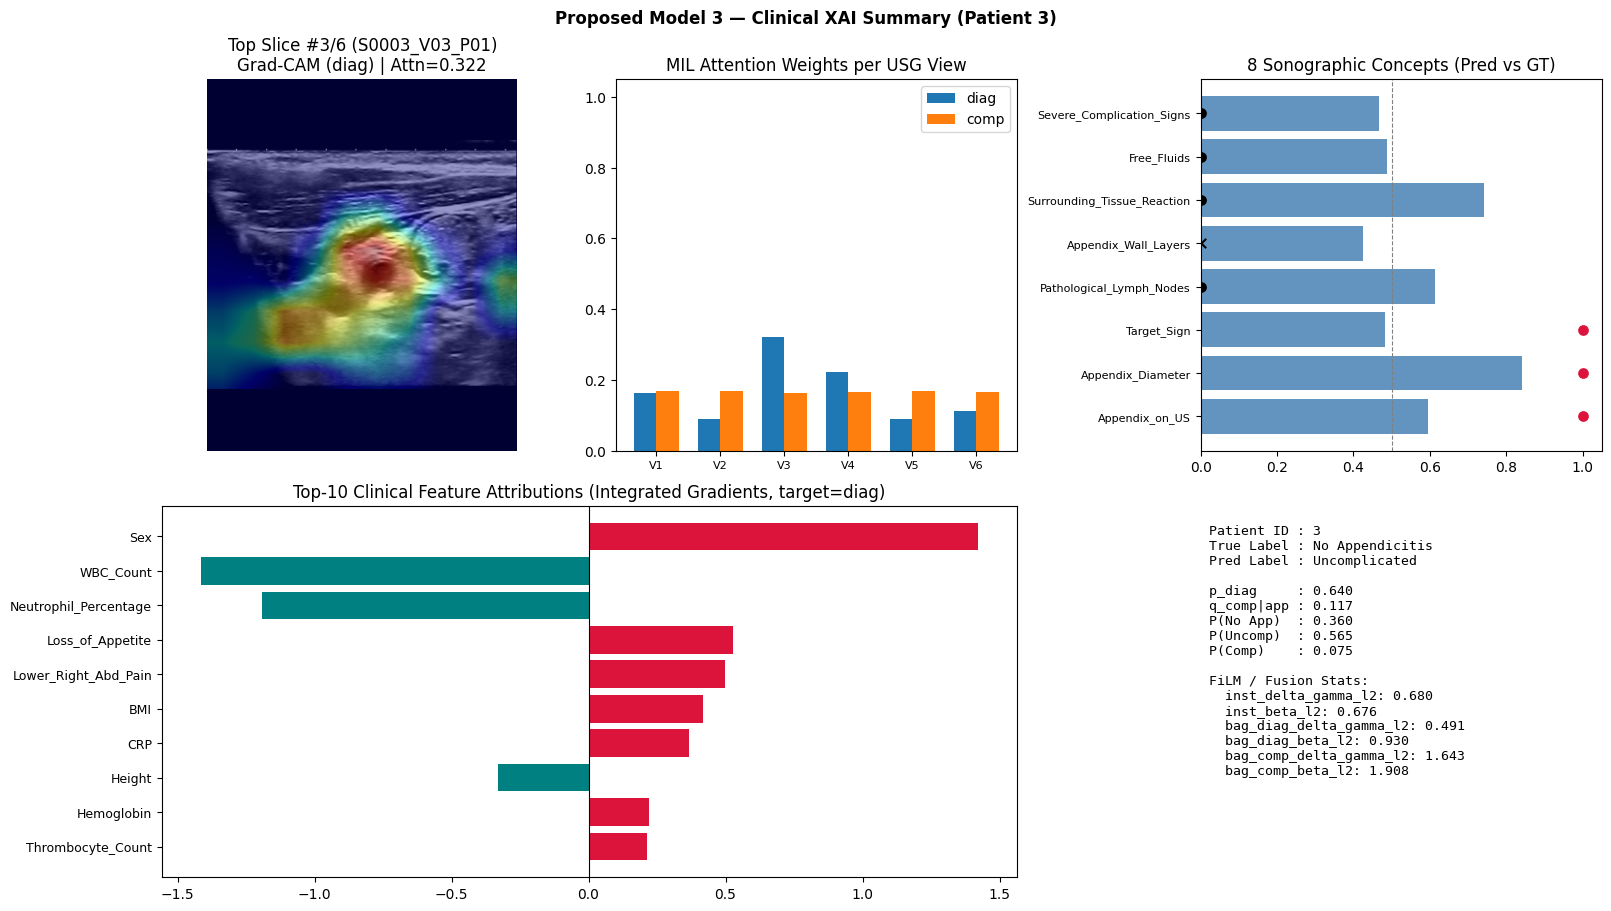

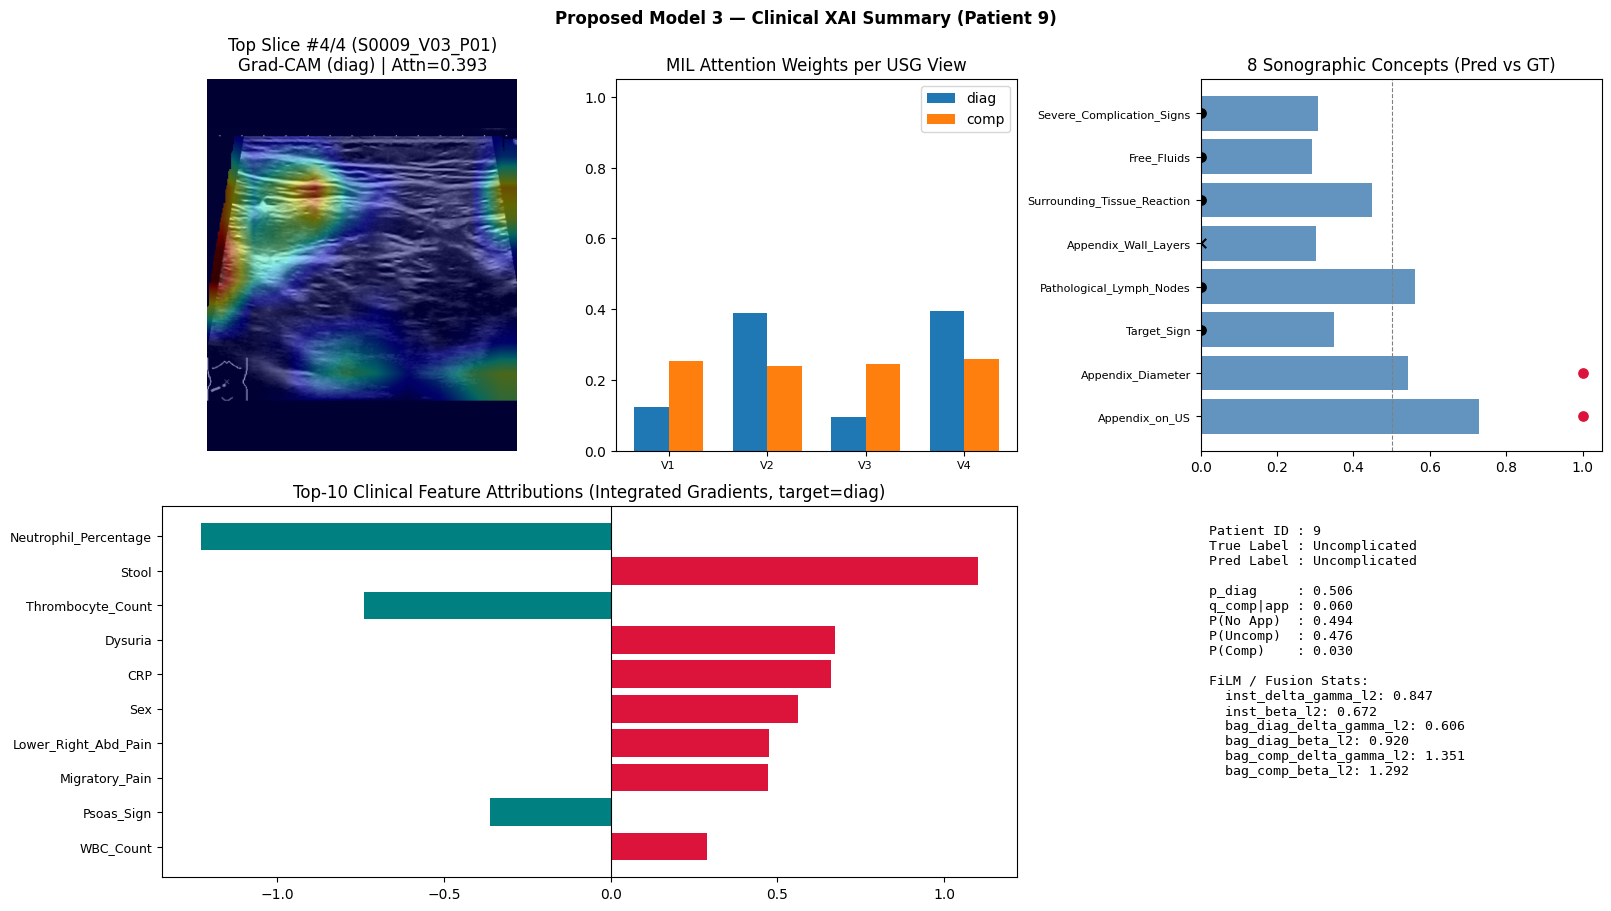

In [9]:
if RUN_XAI_DASHBOARD:
    import joblib
    from pm3_data import ClinicalPipeline, PM3PatientBagDataset
    from pm3_model import PM3Model
    from pm3_xai import explain_patient

    canon_dir = canonical_multimodal_all_dir("hierarchical")
    ckpt_path = canon_dir / "fold_1" / "model" / "best_model.pt"
    if not ckpt_path.exists():
        print(f"Checkpoint XAI belum tersedia di {ckpt_path}. Selesaikan 02 Bagian 1 terlebih dahulu.")
    else:
        pipe_path = canon_dir / "fold_1" / "data" / "clinical_pipeline.joblib"
        if pipe_path.exists():
            pipe = joblib.load(pipe_path)
        else:
            fold1 = folds[0]
            pipe = ClinicalPipeline().fit(cohort.loc[fold1["train"]])

        fold1_val_ids = folds[0]["val"]
        val_ds = PM3PatientBagDataset(
            ids=fold1_val_ids,
            cohort=cohort,
            clinical_pipeline=pipe,
            bags=bags_by_mode["all"],
            cache=cache,
            train=False,
        )
        mcfg_xai = ModelConfig(
            clinical_dim=len(getattr(pipe, "columns_", [])) or 28,
            num_concepts=8,
            modality="multimodal",
            backbone_mode=BEST_BACKBONE,
            aggregator="cross_attn",
            fusion_mode="film",
            task_mode="hierarchical",
            use_concepts=True,
        )
        model_xai = PM3Model(mcfg_xai).to(DEVICE)
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        state = (
            ckpt["model_state"] if isinstance(ckpt, dict) and "model_state" in ckpt
            else ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt
            else ckpt
        )
        model_xai.load_state_dict(state)
        model_xai.eval()

        xai_out_dir = PM3_DIR / "runs" / "03_xai_examples"
        xai_out_dir.mkdir(parents=True, exist_ok=True)
        # Ambil hingga 2 pasien validasi fold 1
        sample_indices = [0]
        if len(val_ds) > 1:
            sample_indices.append(1)
        for idx in sample_indices:
            item = val_ds[idx]
            pid = item["patient_id"]
            save_p = xai_out_dir / f"xai_fold1_pid_{pid}.png"
            fig = explain_patient(
                model=model_xai,
                item=item,
                device=DEVICE,
                feature_names=getattr(pipe, "columns_", None),
                save_path=save_p,
                target="diag",
            )
            print(f"XAI pasien {pid} tersimpan -> {save_p}")
else:
    print("RUN_XAI_DASHBOARD=False, dilewati.")
